# Temperature anisotropy instability for whistler waves

The dispersion relation for the whistler mode ($\sqrt{|\Omega_i\Omega_e|}<\omega<|\Omega_e|$) in the quasi-longitudinal (QL) limit ($\Omega_e^2\sin^4\theta\ll 4\omega^{-2}(\omega^2-\omega_{pe}^2)^2\cos^2\theta$) is given by
$$n^2=1-\frac{\omega_{pe}^2}{\omega(\omega-|\Omega_e\cos\theta|)}.$$ 
This dispersion relation can be further simplified as
$$n^2=\frac{\omega_{pe}^2}{\omega(|\Omega_e\cos\theta|-\omega)},$$ since $n\gg 1$ if $|\omega_{pe}/\Omega_e|>1$.
The following code will use the first dispersion relation.

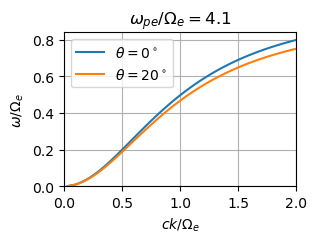

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
plt.figure(figsize=(3,2))
wpewce=4.1; i=0
w=np.linspace(0.001,0.8,100)
k0=1./wpewce # convert k from Omega_e/c to omega_pe/c
for th in [0, 20]:
    k=np.sqrt(w**2*(1.-wpewce**2/w/(w-np.cos(th*np.pi/180))))
    line,=plt.plot(k*k0,w,label=r'$\theta=%d^\circ$'%th)
    if th==0:
        k_theory=k*k0
        w_theory=w
plt.title(r'$\omega_{pe}/\Omega_e=%.1f$'%wpewce);plt.legend(loc='best');plt.xlim(0,2.);plt.ylim(0,)
plt.xlabel(r'$ck/\Omega_{e}$');plt.ylabel(r'$\omega/\Omega_{e}$');plt.grid()
plt.show()

The following code uses an approximation for growth rate calculation as in Gary (1993).

n_e = 2.3180818357225492 ,B0= 0.00119 ,wpewce= 4.1
beta_1= 0.003298449896886474
w width= [0.34222222]
max growth rate= 0.007227929104809886
w_max_position [0.35666667]


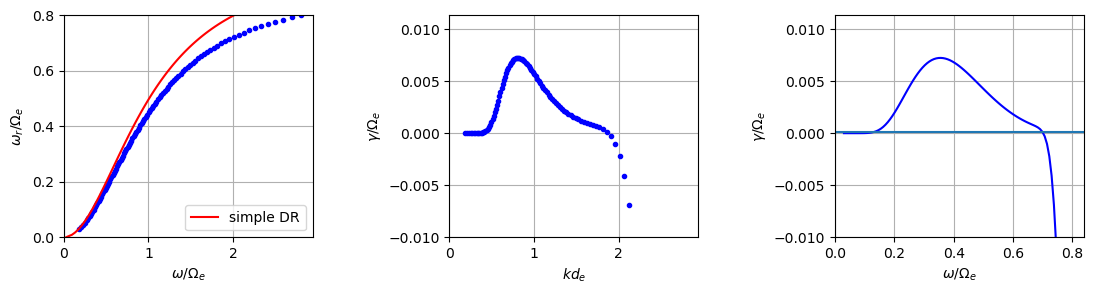

In [2]:
import parallel_growth as cd
from scipy.signal import find_peaks, peak_widths
from IPython.display import display, Math
def mprint(s):
    display(Math(s))

plt.rc('font',size=10)
BG=119*1e-5 # assume some magnetic field, in Gauss
ne=(1.76e7*BG*wpewce/5.64e4)**2
print('n_e =', ne, ',B0=', BG, ',wpewce=', wpewce)
mass=[1.,1836.,1.]    # mass unit m_e for three species (cold es, is, & hot e) 
charge=[-1,1,-1]      # charge unit e
ww=[];wp=[]; gm=[];wwf=[]
# aa=np.linspace(5000,2000,25)
for A in [10000]:
    density=[.994,1.0,.006]    # relative density
    temp=[50,50, A]    # parallel temperature, eV
    anis=[1.,1., 6.0]
    name=['e','H','e'];sym=['-.','--',':','-']
    min_freq=[0.03];max_freq=[0.8];color=['b','r']
    beta_1=4.03e-11*ne*temp[0]/BG**2;print('beta_1=',beta_1)
    # check density
    den=0.
    for i in range(len(mass)):
      den+=density[i]*charge[i]
    if abs(den)>1e-6:
      print('Non-neutral!! den=%f\n'%den)
      exit()
    
    plt.figure(figsize=(12,3))
    ax1=plt.subplot(131);ax2=plt.subplot(132);ax3=plt.subplot(133)
    for iband in range(len(min_freq)):
      o_min=min_freq[iband]
      o_max=max_freq[iband]
      # run my Python code
      k0=1./wpewce*np.sqrt(mass[0]/charge[0]**2) # convert k from c/|omega_ce| to c/omega_p1
      w0=mass[0]/abs(charge[0]) # convert omega from |omega_ce| to |omega_c1|
      th=25
      lhk=[];lhw=[];lhg=[];lzeta=[];rhk=[];rhw=[];rhg=[];rzeta=[]
      for w in np.linspace(o_min,o_max,100):
        n2=cd.dispersion_w(w,th,wpewce,mass,density,charge)
        for j in range(2):
          if n2[j]>0:
            polar=(n2[j]-n2[5])/n2[6] # polarization 
            k=np.sqrt(n2[j])*w
            zeta=[]
            if polar < 0: # LHP
              lhk.append(k) # k in unit c/omega_ce
              lhw.append(w)
              g,zeta=cd.growth(w,k,-1.,wpewce,mass,density,charge,temp,anis)
              lhg.append(g)
              lzeta.append(zeta)
            else: #RHP
              rhk.append(k) # k in unit c/omega_ce
              rhw.append(w)
              g,zeta=cd.growth(w,k,1.,wpewce,mass,density,charge,temp,anis)
              rhg.append(g)
              rzeta.append(zeta)
      lhk=np.array(lhk);lhw=np.array(lhw);lhg=np.array(lhg);lzeta=np.array(lzeta)
      rhk=np.array(rhk);rhw=np.array(rhw);rhg=np.array(rhg);rzeta=np.array(rzeta)
      # print(lhk.shape)
      if mass[0]>1:
        ax1.plot(lhk*k0,lhw*w0, '.',color=color[iband])
        ax2.plot(lhk*k0,lhg*w0, '.',color=color[iband])
        kmin=lhk[0]*k0*np.sqrt(beta_1)
        kmax=lhk[-1]*k0*np.sqrt(beta_1)
        ax3.plot(lhw*w0,lhg*w0,'-',color=color[iband])
        ax3.plot(lhk*k0,lhg/lhw, '--',color=color[iband])
      else:
        ax1.plot(rhk*k0,rhw*w0, '.',color=color[iband])
        ax2.plot(rhk*k0,rhg*w0, '.',color=color[iband])
        kmin=rhk[0]*k0*np.sqrt(beta_1)
        kmax=rhk[-1]*k0*np.sqrt(beta_1)
        vg=(rhw[1:]-rhw[0:-1])/(rhk[1:]-rhk[0:-1])
        ax3.plot(rhw*w0,rhg*w0,'-',color=color[iband])
        w_position= rhw[np.where(rhg==max(rhg))[0]]*w0 #rhw[peak]*w0
        gamma_max=max(rhg*w0)
        target = 0.0001
        ax3.axhline(target)
        idxx = np.where(np.diff(np.sign(rhg - target)) != 0)[0]
        w_at = rhw[idxx]
        w_wdth=(w_at[1]-rhw[np.where(rhg==max(rhg))[0]])*w0
        ww.append(w_wdth)
        wp.append(w_position)
        gm.append(gamma_max)
        print("w width=", w_wdth)
        print('max growth rate=', gamma_max)
        print(r'w_max_position', rhw[np.where(rhg==max(rhg))[0]]*w0) 
    ax1.grid();ax1.set_ylabel(r'$\omega_r/\Omega_%s$'%name[0])
    ax1.set_xlabel(r'$\omega/\Omega_%s$'%name[0])
    ax1.set_xlim(0,);ax1.set_ylim(0,max(max_freq)*mass[0])
    # ax1.legend(loc='best')
    ax2.set_ylabel(r'$\gamma/\Omega_%s$'%name[0]);ax2.set_xlabel(r'$k d_%s$'%name[0])
    ax2.set_xlim(0,);ax2.set_ylim(-0.01,);ax2.grid()
    # ax2.legend(loc='best')
    ax3.set_ylabel(r'$\gamma/\Omega_%s$'%name[0]);ax3.set_xlabel(r'$\omega/\Omega_%s$'%name[0])
    ax3.set_xlim(0,);ax3.set_ylim(-0.01,);ax3.grid()
    # overplot with theoretical curves
    ax1.plot(k_theory, w_theory, color='r',label='simple DR')
    # ax1.set_title(r'$\theta=%g,\,\omega_{pe}/\omega_{ce}=%g$'%(th,wpewce))
    ax1.legend()
    plt.subplots_adjust(left=.1,right=.95,top=.88,bottom=.14,hspace=.4,wspace=.55)
    plt.show()

# np.savetxt('aaa.dat',aa)
# np.savetxt('wwt.dat',ww)
# np.savetxt('wwfa.dat',wwf)
# np.savetxt('wpa.dat',wp)
# np.savetxt('gma.dat',gm)

In [3]:
def pltmd(axt,c,right):
  axt.minorticks_on()
  axt.tick_params(axis='both', which='both', color=c,
                  direction='in', top=True, right=right)

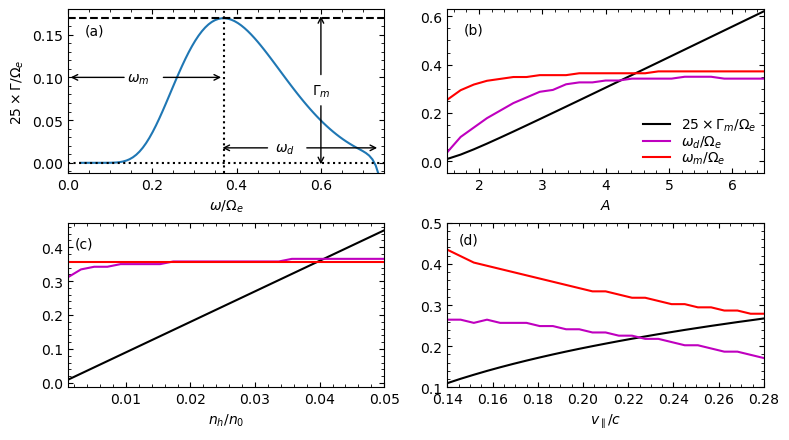

In [4]:
plt.rc('font',size=10);
from matplotlib.gridspec import GridSpec
fig = plt.figure(figsize=(8, 4.25))
gs = GridSpec(2, 2, figure=fig,hspace=0.3,wspace=0.2)
ax1 = fig.add_subplot(gs[0, 0]); ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, 0]); ax4 = fig.add_subplot(gs[1, 1])
g1 = np.loadtxt('g_ans_6_10000_.006.dat'); w1 = np.loadtxt('w_ans_6_10000_.006.dat')
aaa = np.loadtxt('aaa.dat'); wpa = np.loadtxt('wpa.dat');gma = np.loadtxt('gma.dat'); wwa = np.loadtxt('wwa.dat') # variation with A
aanh = np.loadtxt('aanh.dat'); wpnh = np.loadtxt('wpnh.dat'); wwnh = np.loadtxt('wwnh.dat');gmnh = np.loadtxt('gmnh.dat') # variation with nh
aat = np.loadtxt('aat.dat'); wpt = np.loadtxt('wpt.dat'); wwt = np.loadtxt('wwt.dat'); gmt = np.loadtxt('gmt.dat') # variations with parallel temperaure

ax1.plot(w1,np.array(g1)*25,label='C3')
ax1.axhline(0.0001,color='k',ls=':')#,xmin=.2,xmax=.98)
ax1.axhline(max(np.array(g1)*25),color='k',ls='--')#, xmin=.3,xmax=.7)
# ax1.axvline(.73, color='k',ls='-.')#, xmin=.3,xmax=.7)
ax1.axvline(.37,color='k',ls=':')
ax2.plot(aaa,np.array(gma)*25,'k',label=r'$25 \times \Gamma_m/\Omega_e$')
# ax2.plot(aaa,wwa,'g',label=r'$\omega_d/\Omega_e$')
ax2.plot(aaa,wwa,'m',label=r'$\omega_d/\Omega_e$')
ax2.plot(aaa,wpa,'r',label=r'$\omega_m/\Omega_e$')
ax2.legend(loc='lower right',ncol=1,borderpad=.001,
           labelspacing=.01,prop={'size':10},frameon=False)
# ax1.legend(loc='upper right',ncol=1,borderpad=.001,
           # labelspacing=.01,prop={'size':10},frameon=False)

ax3.plot(aanh, np.array(gmnh)*25,'k')
# ax3.plot(aanh, wwnh,'g')
ax3.plot(aanh, wwnh,'m')
ax3.plot(aanh, wpnh,'r')
vpara=np.linspace(.14,.28,len(aat))

# ax4.plot(np.array(aat)/1000, np.array(gmt)*25,'k')
# # ax4.plot(np.array(aat)/1000, wwt,'g')
# ax4.plot(np.array(aat)/1000, wpt,'r')
# ax4.plot(np.array(aat)/1000, wwft,'m')

ax4.plot(vpara, np.array(gmt)*25,'k')
# ax4.plot(np.array(aat)/1000, wwt,'g')
ax4.plot(vpara, wpt,'r')
ax4.plot(vpara, wwt,'m')

ax1.set_xlabel(r'$\omega/\Omega_e$');ax1.set_ylabel(r'$25\times \Gamma/\Omega_e$')
ax1.set_ylim(-.0005*25,.18);ax1.set_xlim(.0,.75);pltmd(ax1,'k',True)
ax1.tick_params(axis='y')
ax2.set_xlabel(r'$A$');#ax2.set_ylabel(r'$\gamma_m/\Omega_e$')
pltmd(ax2,'k',True);ax2.set_xlim(1.5,6.5);ax2.set_ylim(-0.05,.63)
ax3.set_xlabel(r'$n_h/n_0$');#ax3.set_ylabel(r'$\gamma_m/\Omega_e$')
pltmd(ax3,'k',True);ax3.set_xlim(.001,.05)
ax4.set_xlabel(r'$v_{\parallel}/c$');pltmd(ax4,'k',True);ax4.set_xlim(.14,.28); ax4.set_ylim(.1,.5)

ax1.annotate('', xy=(0.36, 0.0175), xytext=(0.48, 0.0175), arrowprops=dict(arrowstyle='->', lw=1))
ax1.text(.49,.013,r'$\omega_d$')
ax1.annotate('', xy=(0.74, 0.0175), xytext=(0.56, 0.0175), arrowprops=dict(arrowstyle='->', lw=1))
ax1.annotate('', xy=(0.0, 0.1), xytext=(0.14, 0.1), arrowprops=dict(arrowstyle='->', lw=1))
ax1.text(.14,.095,r'$\omega_m$')
ax1.annotate('', xy=(0.37, 0.1), xytext=(0.22, 0.1), arrowprops=dict(arrowstyle='->', lw=1))
ax1.annotate('', xy=(.6, -0.005), xytext=(.6, 0.07), arrowprops=dict(arrowstyle='->', lw=1))
ax1.text(.58,.08,r'$\Gamma_m$')
ax1.annotate('', xy=(0.6, 0.175), xytext=(0.6, 0.10), arrowprops=dict(arrowstyle='->', lw=1))
ax1.text(.04,.15,'(a)');ax2.text(1.75,.53,'(b)');ax3.text(.002,.4,'(c)');ax4.text(.145,.45,'(d)')
ax2.yaxis.set_label_coords(-.3, 0.2)
plt.subplots_adjust(left=.12,right=.99,top=.99,bottom=0.10)
plt.savefig('/Users/vshankar/Documents/Chorus/paper_plot/disp.pdf')
plt.show()